# Porównanie Polska / Niemcy / Czechy

Celem jest porównanie prędkości deformacji i liczby anomalii w trzech krajach wokół odkrywki Turów.

Porównanie robimy na dwóch poziomach:

1. **budynki** – plik `budynki_EGMS_results.gpkg` ma gotową kolumnę `kraj`, a budynki mają przypisany najbliższy PS (do 30 m),
2. **punkty PS** – plik `EGMS_Turow_U_results.csv` nie ma kolumny `kraj`, więc każdemu PS przypisujemy kraj najbliższego budynku.

Notatnik korzysta tylko z gotowych wyników i nie zmienia notatników bazowych.

## Wczytanie danych

In [1]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

buildings = gpd.read_file("budynki_EGMS_results.gpkg")
ps = pd.read_csv("EGMS_Turow_U_results.csv")

print("Liczba budynków:", len(buildings))
print("Liczba PS:", len(ps))
print("CRS budynków:", buildings.crs)

Liczba budynków: 39156
Liczba PS: 6268
CRS budynków: EPSG:3035


In [2]:
# Kolumna anomaly w pliku z budynkami jest zapisana jako tekst ("True"/"False"),
# a budynki bez PS mają wartość pustą - zamieniamy ją na True/False
buildings["anomaly"] = buildings["anomaly"] == "True"

print(buildings["kraj"].value_counts())

kraj
DE    23101
PL     8799
CZ     7256
Name: count, dtype: int64


## Porównanie na poziomie budynków

Do statystyk prędkości bierzemy tylko budynki, które mają przypisany PS w odległości do 30 m (`has_PS_30m`).

In [3]:
kraje = ["PL", "DE", "CZ"]

tabela_budynki = pd.DataFrame(index=kraje)

tabela_budynki["liczba_budynkow"] = buildings.groupby("kraj").size()
tabela_budynki["budynki_z_PS"] = buildings.groupby("kraj")["has_PS_30m"].sum()
tabela_budynki["procent_z_PS"] = (
    tabela_budynki["budynki_z_PS"] / tabela_budynki["liczba_budynkow"] * 100
).round(1)

z_ps = buildings[buildings["has_PS_30m"]]

tabela_budynki["srednia_predkosc"] = z_ps.groupby("kraj")["mean_velocity"].mean().round(2)
tabela_budynki["mediana_predkosci"] = z_ps.groupby("kraj")["mean_velocity"].median().round(2)
tabela_budynki["min_predkosc"] = z_ps.groupby("kraj")["mean_velocity"].min()
tabela_budynki["budynki_z_anomalia"] = z_ps.groupby("kraj")["anomaly"].sum()
tabela_budynki["procent_anomalii"] = (
    tabela_budynki["budynki_z_anomalia"] / tabela_budynki["budynki_z_PS"] * 100
).round(2)

tabela_budynki

,liczba_budynkow,budynki_z_PS,procent_z_PS,srednia_predkosc,mediana_predkosci,min_predkosc,budynki_z_anomalia,procent_anomalii
PL,8799,3562,40.5,-1.17,-0.6,-9.4,0,0.00
DE,23101,9052,39.2,-1.90,-1.2,-9.2,6,0.07
CZ,7256,2762,38.1,-1.63,-0.8,-8.9,0,0.00


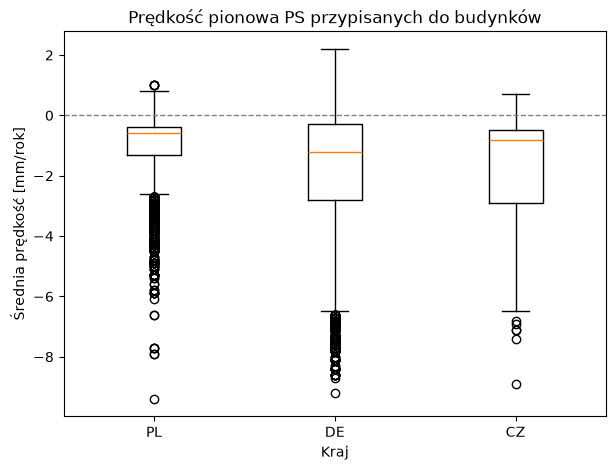

In [4]:
fig, ax = plt.subplots(figsize=(7, 5))

dane = [z_ps.loc[z_ps["kraj"] == k, "mean_velocity"] for k in kraje]
ax.boxplot(dane, tick_labels=kraje)

ax.axhline(0, color="grey", linestyle="--", linewidth=1)
ax.set_xlabel("Kraj")
ax.set_ylabel("Średnia prędkość [mm/rok]")
ax.set_title("Prędkość pionowa PS przypisanych do budynków")

plt.show()

In [5]:
# Udział budynków w poszczególnych klastrach K-means w każdym kraju [%]
klastry_budynki = pd.crosstab(z_ps["kraj"], z_ps["cluster"], normalize="index") * 100
klastry_budynki.round(1)

cluster,0.0,1.0,3.0
kraj,,,
CZ,18.6,81.4,0.0
DE,30.3,69.7,0.0
PL,24.2,75.6,0.2


Na poziomie budynków anomalii jest bardzo mało, bo prawie wszystkie anomalne PS leżą w obrębie odkrywki i zwałowiska, gdzie nie ma budynków. Dlatego porównujemy też same punkty PS.

## Przypisanie kraju do punktów PS

Każdemu PS przypisujemy kraj najbliższego budynku (`sjoin_nearest` bez limitu odległości). Jest to przybliżenie – przy samej granicy punkt może dostać kraj z drugiej strony granicy, a punkty w kopalni dostają kraj najbliższych zabudowań. Odległość do budynku zapisujemy w kolumnie `odl_do_budynku`, żeby było widać, które punkty leżą daleko od zabudowy.

In [6]:
ps_gdf = gpd.GeoDataFrame(
    ps,
    geometry=gpd.points_from_xy(ps["easting"], ps["northing"]),
    crs="EPSG:3035"
)

buildings = buildings.to_crs(ps_gdf.crs)

ps_kraj = gpd.sjoin_nearest(
    ps_gdf,
    buildings[["kraj", "geometry"]],
    how="left",
    distance_col="odl_do_budynku"
)

# Jeśli PS ma kilka budynków w tej samej odległości, zostawiamy pierwszy
ps_kraj = ps_kraj.drop_duplicates(subset="pid", keep="first")

print("Liczba PS:", len(ps_kraj))
print(ps_kraj["kraj"].value_counts())

Liczba PS: 6268
kraj
PL    2641
DE    2227
CZ    1400
Name: count, dtype: int64


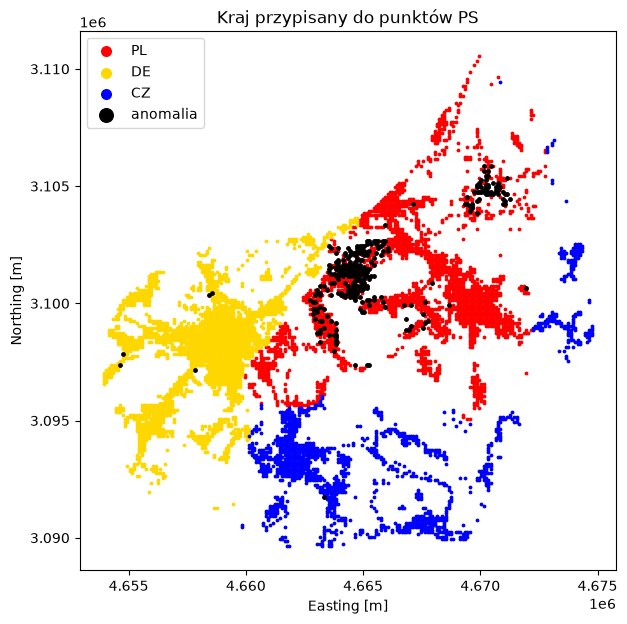

In [7]:
fig, ax = plt.subplots(figsize=(8, 7))

kolory = {"PL": "red", "DE": "gold", "CZ": "blue"}

for k in kraje:
    punkty = ps_kraj[ps_kraj["kraj"] == k]
    ax.scatter(punkty["easting"], punkty["northing"], s=3, color=kolory[k], label=k)

anomalie = ps_kraj[ps_kraj["anomaly"]]
ax.scatter(anomalie["easting"], anomalie["northing"], s=6, color="black", label="anomalia")

ax.set_title("Kraj przypisany do punktów PS")
ax.set_xlabel("Easting [m]")
ax.set_ylabel("Northing [m]")
ax.set_aspect("equal")
ax.legend(markerscale=4)

plt.show()

## Porównanie na poziomie punktów PS

In [8]:
tabela_ps = pd.DataFrame(index=kraje)

tabela_ps["liczba_PS"] = ps_kraj.groupby("kraj").size()
tabela_ps["srednia_predkosc"] = ps_kraj.groupby("kraj")["mean_velocity"].mean().round(2)
tabela_ps["mediana_predkosci"] = ps_kraj.groupby("kraj")["mean_velocity"].median().round(2)
tabela_ps["min_predkosc"] = ps_kraj.groupby("kraj")["mean_velocity"].min()
tabela_ps["liczba_anomalii"] = ps_kraj.groupby("kraj")["anomaly"].sum()
tabela_ps["procent_anomalii"] = (
    tabela_ps["liczba_anomalii"] / tabela_ps["liczba_PS"] * 100
).round(2)
tabela_ps["udzial_we_wszystkich_anomaliach"] = (
    tabela_ps["liczba_anomalii"] / ps_kraj["anomaly"].sum() * 100
).round(1)

tabela_ps

,liczba_PS,srednia_predkosc,mediana_predkosci,min_predkosc,liczba_anomalii,procent_anomalii,udzial_we_wszystkich_anomaliach
PL,2641,-8.33,-1.7,-75.3,308,11.66,98.1
DE,2227,-1.68,-0.9,-9.2,5,0.22,1.6
CZ,1400,-1.42,-0.7,-9.7,1,0.07,0.3


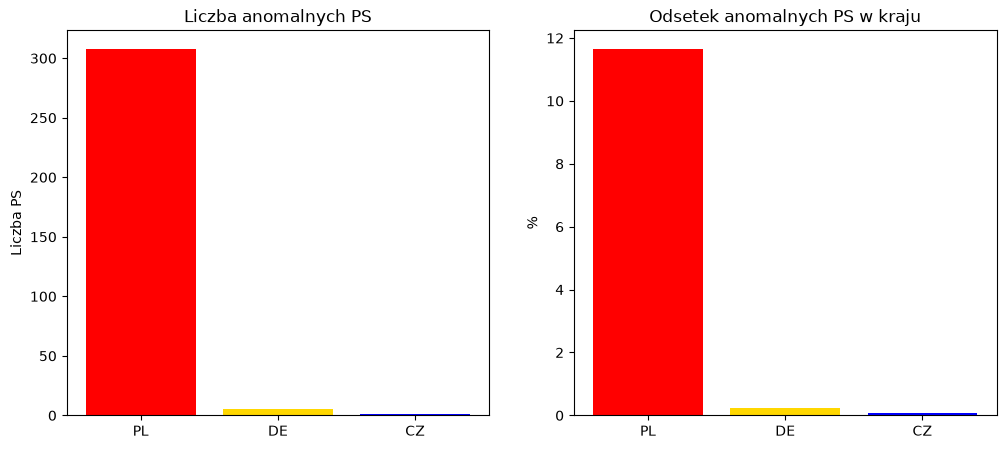

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].bar(tabela_ps.index, tabela_ps["liczba_anomalii"], color=["red", "gold", "blue"])
axes[0].set_title("Liczba anomalnych PS")
axes[0].set_ylabel("Liczba PS")

axes[1].bar(tabela_ps.index, tabela_ps["procent_anomalii"], color=["red", "gold", "blue"])
axes[1].set_title("Odsetek anomalnych PS w kraju")
axes[1].set_ylabel("%")

plt.show()

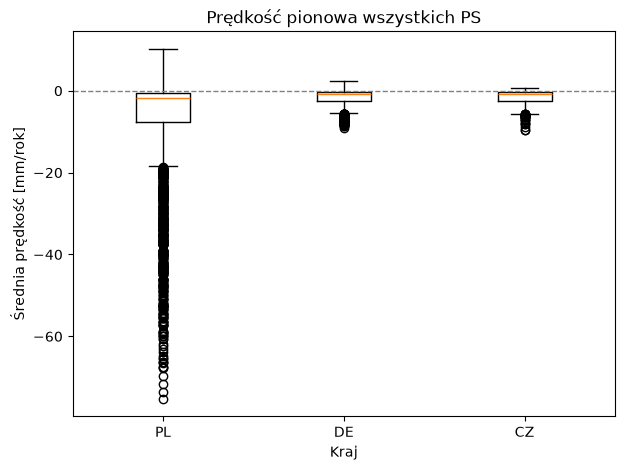

In [10]:
fig, ax = plt.subplots(figsize=(7, 5))

dane = [ps_kraj.loc[ps_kraj["kraj"] == k, "mean_velocity"] for k in kraje]
ax.boxplot(dane, tick_labels=kraje)

ax.axhline(0, color="grey", linestyle="--", linewidth=1)
ax.set_xlabel("Kraj")
ax.set_ylabel("Średnia prędkość [mm/rok]")
ax.set_title("Prędkość pionowa wszystkich PS")

plt.show()

In [11]:
# Udział PS w poszczególnych klastrach K-means w każdym kraju [%]
klastry_ps = pd.crosstab(ps_kraj["kraj"], ps_kraj["cluster"], normalize="index") * 100
klastry_ps.round(1)

cluster,0,1,2,3
kraj,,,,
CZ,21.9,78.1,0.0,0.1
DE,32.8,67.1,0.0,0.1
PL,25.1,55.0,9.2,10.8


## Porównanie bez punktów kopalni

Punkty z klastrów szybkiego osiadania (ok. −31 mm/rok) leżą prawie wyłącznie w odkrywce i na zwałowisku, więc mocno zaniżają średnią prędkość w kraju, do którego zostały przypisane. Żeby porównać sam teren poza kopalnią, liczymy statystyki jeszcze raz bez tych klastrów.

In [12]:
# Klastry szybkiego osiadania = klastry ze średnią prędkością poniżej -10 mm/rok
srednie_klastrow = ps_kraj.groupby("cluster")["mean_velocity"].mean()
print(srednie_klastrow.round(2))

klastry_kopalni = srednie_klastrow[srednie_klastrow < -10].index.tolist()
print("Klastry kopalni:", klastry_kopalni)

cluster
0    -1.68
1    -2.02
2   -31.06
3   -31.90
Name: mean_velocity, dtype: float64
Klastry kopalni: [2, 3]


In [13]:
poza_kopalnia = ps_kraj[~ps_kraj["cluster"].isin(klastry_kopalni)]

tabela_bez_kopalni = pd.DataFrame(index=kraje)

tabela_bez_kopalni["liczba_PS"] = poza_kopalnia.groupby("kraj").size()
tabela_bez_kopalni["srednia_predkosc"] = poza_kopalnia.groupby("kraj")["mean_velocity"].mean().round(2)
tabela_bez_kopalni["mediana_predkosci"] = poza_kopalnia.groupby("kraj")["mean_velocity"].median().round(2)
tabela_bez_kopalni["liczba_anomalii"] = poza_kopalnia.groupby("kraj")["anomaly"].sum()
tabela_bez_kopalni["procent_anomalii"] = (
    tabela_bez_kopalni["liczba_anomalii"] / tabela_bez_kopalni["liczba_PS"] * 100
).round(2)

tabela_bez_kopalni

,liczba_PS,srednia_predkosc,mediana_predkosci,liczba_anomalii,procent_anomalii
PL,2114,-2.51,-1.0,28,1.32
DE,2225,-1.68,-0.8,5,0.22
CZ,1399,-1.42,-0.7,1,0.07


## Zapis wyników

Zapisujemy punkty PS z kolumną `kraj` do GeoPackage, żeby inni mogli ich użyć (np. do map w QGIS).

In [14]:
ps_kraj.drop(columns=["index_right"]).to_file(
    "PS_kraj.gpkg",
    layer="PS_kraj",
    driver="GPKG"
)

print("Zapisano: PS_kraj.gpkg")

Zapisano: PS_kraj.gpkg


## Wnioski

- **Budynki:** odsetek budynków z PS w promieniu 30 m jest podobny we wszystkich krajach (38–41%). Średnia prędkość pod budynkami jest niewielka: PL −1,17, CZ −1,63, DE −1,90 mm/rok. Anomalie mają tylko 6 budynków, wszystkie w Niemczech, więc na poziomie budynków kraje praktycznie się nie różnią.
- **Punkty PS:** 308 z 314 anomalii (98%) przypada na Polskę, bo tam leży odkrywka i zwałowisko. Przez to średnia prędkość PS w PL wynosi −8,33 mm/rok, a minimum −75 mm/rok, wobec ok. −1,4 do −1,7 mm/rok w DE i CZ. Klastry szybkiego osiadania (2 i 3) występują prawie wyłącznie w PL (20% punktów).
- **Bez kopalni:** po usunięciu klastrów 2 i 3 różnice mocno maleją: średnia prędkość PL −2,51, DE −1,68, CZ −1,42 mm/rok. Polska nadal ma najwięcej anomalii (28 PS, 1,3%), prawdopodobnie na obrzeżach kopalni, które nie weszły do klastrów kopalni.
- Kraj PS przypisano na podstawie najbliższego budynku, więc przy granicy wynik jest przybliżony. Dokładniej byłoby użyć poligonów granic państw.